In [2]:
import os
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split, Subset
from torchvision import datasets, transforms, models
from PIL import Image
import matplotlib
from tqdm.auto import tqdm
# matplotlib.use(\"Agg\")
import matplotlib.pyplot as plt
%matplotlib inline


In [3]:
# --- 1. Настройки ---
DATA_DIR = "D:/python_programming/for_git_repositories/work_folder/STUDY/0._DL1._Классификация"
TRAIN_DIR = os.path.join(DATA_DIR, 'train')
TEST_DIR = os.path.join(DATA_DIR, 'test')

BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 1e-4
IMAGE_SIZE = 128
VAL_SPLIT = 0.2  # 20% тренировочных данных пойдет на валидацию
num_workers = 0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {device}")

Используемое устройство: cpu


In [4]:
# --- 2. Загрузка и подготовка данных ---
# Трансформации для тренировочных данных (с аугментацией)
train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Трансформации для валидации и теста (без аугментации)
val_test_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Загружаем полный тренировочный датасет
full_train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
class_names = full_train_dataset.classes
num_classes = len(class_names)
print(f"Найдено классов ({num_classes}): {class_names}")

# Разделяем тренировочный датасет на train и validation
val_size = int(len(full_train_dataset) * VAL_SPLIT)
train_size = len(full_train_dataset) - val_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

# Важно: для валидационной части нужно применить другие трансформации (без аугментации)
# Перезаписываем transform для валидационной подвыборки
# val_dataset.dataset.transform = val_test_transforms

full_ds_for_train = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
full_ds_for_val   = datasets.ImageFolder(TRAIN_DIR, transform=val_test_transforms)

val_size   = int(len(full_ds_for_train) * VAL_SPLIT)
train_size = len(full_ds_for_train) - val_size

# один и тот же random_seed — чтобы индексы совпали
g = torch.Generator().manual_seed(42)
indices = torch.randperm(len(full_ds_for_train), generator=g).tolist()
train_idx, val_idx = indices[:train_size], indices[train_size:]

train_dataset = Subset(full_ds_for_train, train_idx)
val_dataset   = Subset(full_ds_for_val,   val_idx)

# Создаем DataLoader'ы
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=num_workers)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=num_workers)

# Тестовый датасет (без подпапок) можно загрузить позже, если нужно сделать предсказания.
# Для построения графиков на этапе обучения он не обязателен.


Найдено классов (10): ['butterfly', 'cat', 'chicken', 'cow', 'dog', 'elephant', 'horse', 'sheep', 'spider', 'squirrel']


In [5]:
# --- 3. Создание модели с замороженным backbone ---
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# 1) Замораживаем ВСЕ параметры
for param in model.parameters():
    param.requires_grad = False

# 2) Заменяем последний слой — он по умолчанию обучаемый (requires_grad=True)
model.fc = nn.Linear(model.fc.in_features, num_classes)

model = model.to(device)

# 3) В оптимизатор передаём ТОЛЬКО параметры нового слоя
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=LEARNING_RATE)

# Проверка: сколько параметров реально учится
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Обучаемых параметров: {trainable:,} из {total:,} ({100*trainable/total:.2f}%)")

Обучаемых параметров: 5,130 из 11,181,642 (0.05%)


In [6]:
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    # --- Фаза обучения ---
    model.train()
    running_loss = 0.0
    running_corrects = 0

    train_bar = tqdm(train_loader, desc=f"Эпоха {epoch+1}/{EPOCHS} [train]")
    for inputs, labels in train_bar:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        _, preds = torch.max(outputs, 1)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

        # обновляем цифры на прогресс-баре после каждого батча
        processed = (train_bar.n + 1) * BATCH_SIZE
        train_bar.set_postfix({
            'loss': f'{running_loss / processed:.4f}',
            'acc':  f'{running_corrects.item() / processed:.4f}'
        })

    epoch_train_loss = running_loss / train_size
    epoch_train_acc = running_corrects.double() / train_size
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc.item())

    # --- Фаза валидации ---
    model.eval()
    val_loss = 0.0
    val_corrects = 0

    val_bar = tqdm(val_loader, desc=f"Эпоха {epoch+1}/{EPOCHS} [val]  ")
    with torch.no_grad():
        for inputs, labels in val_bar:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            val_loss += loss.item() * inputs.size(0)
            val_corrects += torch.sum(preds == labels.data)

            processed = (val_bar.n + 1) * BATCH_SIZE
            val_bar.set_postfix({
                'loss': f'{val_loss / processed:.4f}',
                'acc':  f'{val_corrects.item() / processed:.4f}'
            })

    epoch_val_loss = val_loss / val_size
    epoch_val_acc = val_corrects.double() / val_size
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc.item())

    print(f"✔ Эпоха {epoch+1}/{EPOCHS} | "
          f"Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}", flush=True)

Эпоха 1/15 [train]:   0%|          | 0/439 [00:00<?, ?it/s]

Эпоха 1/15 [val]  :   0%|          | 0/110 [00:00<?, ?it/s]

✔ Эпоха 1/15 | Train Loss: 1.7298 Acc: 0.4319 | Val Loss: 1.1355 Acc: 0.6804


Эпоха 2/15 [train]:   0%|          | 0/439 [00:00<?, ?it/s]

Эпоха 2/15 [val]  :   0%|          | 0/110 [00:00<?, ?it/s]

✔ Эпоха 2/15 | Train Loss: 1.0515 Acc: 0.6992 | Val Loss: 0.7915 Acc: 0.7841


... (35 outputs left out)

✔ Эпоха 14/15 | Train Loss: 0.5368 Acc: 0.8309 | Val Loss: 0.4629 Acc: 0.8562


Эпоха 15/15 [train]:   0%|          | 0/439 [00:00<?, ?it/s]

Эпоха 15/15 [val]  :   0%|          | 0/110 [00:00<?, ?it/s]

✔ Эпоха 15/15 | Train Loss: 0.5367 Acc: 0.8279 | Val Loss: 0.4732 Acc: 0.8490


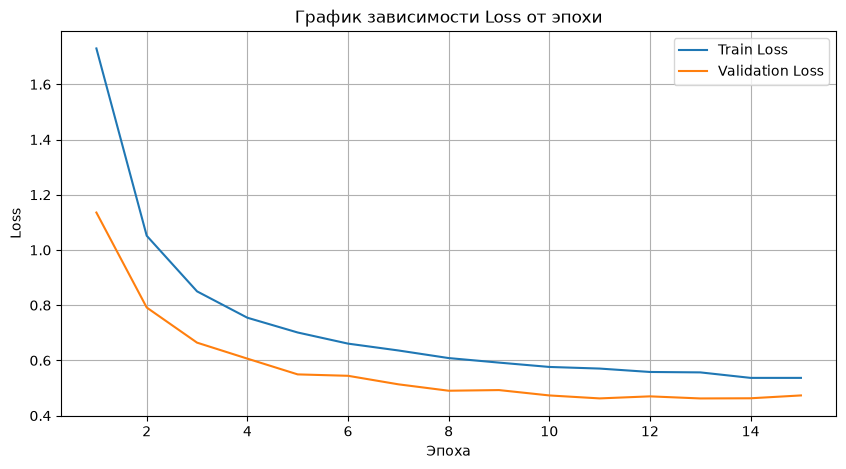

In [7]:
# --- 5. Построение обязательных графиков ---
epochs_range = range(1, EPOCHS + 1)

# График потерь (Loss)
plt.figure(figsize=(10, 5))
plt.plot(epochs_range, history['train_loss'], label='Train Loss')
plt.plot(epochs_range, history['val_loss'], label='Validation Loss')
plt.title('График зависимости Loss от эпохи')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.savefig('loss_plot.png')
plt.show()

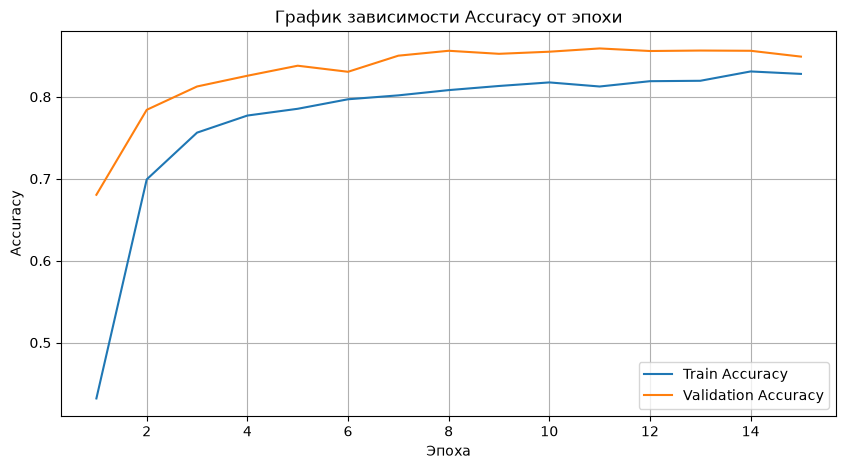

In [8]:
# График точности (Accuracy)
plt.figure(figsize=(10, 5))
plt.plot(epochs_range, history['train_acc'], label='Train Accuracy')
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy')
plt.title('График зависимости Accuracy от эпохи')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.savefig('accuracy_plot.png')
plt.show()